# BOBs — Exploratory Data Analysis

This notebook is a first look at the **Baby Open Brains (BOBs)** dataset before training any segmentation models.

I check how the files are organized, what the MRI scans and labels look like, whether the volumes are consistent, and what information is available about the infants. I also note what might matter later for preprocessing and evaluation.

For now, I focus on **`resampled75`** and use **BOBs9** as the segmentation target. These choices still need to be confirmed with the lab. No preprocessing or training is done here.

I reuse the functions in `src/data_utils.py` where possible.

In [ ]:
from pathlib import Path
from collections import Counter
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

# Locate the project root
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

# Reuse functions from src
from src.datasets.data_utils import (  # noqa: E402
    find_subjects,
    load_nifti,
    inspect_volume,
    count_segmentation_labels,
    check_volume_quality,
)

# BOBs dataset directory
DATA_DIR = PROJECT_ROOT / "data" / "bobs"

print("Project root:", PROJECT_ROOT)
print("BOBs dataset path:", DATA_DIR)
print("Dataset exists:", DATA_DIR.exists())

Project root: C:\Users\yasmi\-brain-mri-foundation-models
BOBs dataset path: C:\Users\yasmi\-brain-mri-foundation-models\data\bobs
Dataset exists: True


## 1. Dataset organization

### 1.1 What is in the BOBs folder?

First, I look at the folders and file types to understand what data we have. BOBs provides **T1w and T2w MRI** and several segmentation versions, sometimes with multiple sessions for one infant.

In [2]:
# Explore the top-level structure of BOBs
if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_DIR}")

print("BOBs top-level contents:\n")

for path in sorted(DATA_DIR.iterdir()):
    print("[DIR] " if path.is_dir() else "[FILE]", path.name)

# Count dataset files by extension
all_files = [path for path in DATA_DIR.rglob("*") if path.is_file()]

file_types = Counter(
    ".nii.gz" if path.name.endswith(".nii.gz") else path.suffix.lower()
    for path in all_files
)

print("\nTotal files:", len(all_files))

display(
    pd.DataFrame(file_types.items(), columns=["File type", "Count"]).sort_values(
        "Count", ascending=False
    )
)

print("\nExample file paths:\n")

for path in sorted(all_files)[:20]:
    print(path.relative_to(DATA_DIR))

BOBs top-level contents:

[DIR]  neonatal_bobsV1.0
[DIR]  resampled75

Total files: 933


,File type,Count
7,.nii.gz,710
2,.json,215
5,.csv,2
3,.tsv,2
0,.tsv#,1
1,.pdf,1
4,.md,1
6,.png,1



Example file paths:

neonatal_bobsV1.0\.~lock.dseg.tsv#
neonatal_bobsV1.0\2024.10.02.616147v2.full.pdf
neonatal_bobsV1.0\dataset_description.json
neonatal_bobsV1.0\dseg.tsv
neonatal_bobsV1.0\phenotype\sessions.json
neonatal_bobsV1.0\phenotype\sessions.tsv
neonatal_bobsV1.0\README.md
neonatal_bobsV1.0\sub-116056\ses-3mo\anat\sub-116056_ses-3mo_space-INFANTMNIacpc_desc-aseg_dseg.json
neonatal_bobsV1.0\sub-116056\ses-3mo\anat\sub-116056_ses-3mo_space-INFANTMNIacpc_desc-aseg_dseg.nii.gz
neonatal_bobsV1.0\sub-116056\ses-3mo\anat\sub-116056_ses-3mo_space-INFANTMNIacpc_desc-feta_dseg.nii.gz
neonatal_bobsV1.0\sub-116056\ses-3mo\anat\sub-116056_ses-3mo_space-INFANTMNIacpc_desc-fetalisa_dseg.nii.gz
neonatal_bobsV1.0\sub-116056\ses-3mo\anat\sub-116056_ses-3mo_space-INFANTMNIacpc_desc-lisa_dseg.nii.gz
neonatal_bobsV1.0\sub-116056\ses-3mo\anat\sub-116056_ses-3mo_space-INFANTMNIacpc_T1w.json
neonatal_bobsV1.0\sub-116056\ses-3mo\anat\sub-116056_ses-3mo_space-INFANTMNIacpc_T1w.nii.gz
neonatal_bobsV1.

**What I found:** There are two main folders: `neonatal_bobsV1.0` (the original dataset, with several segmentation versions) and `resampled75` (resampled volumes and `aseg`/`bobs9` masks).

I'll use `resampled75` for the rest of the EDA. Its simplified segmentation seems more practical for our project, but I still need to confirm the label mapping and the dataset choice with Daniela.

### 1.2 Inventory and file pairing

I count subjects, imaging sessions, MRI volumes and masks. Then I check that **every session has exactly one** T1w, T2w, BOBs9 and Aseg file. This avoids working with incomplete image–mask pairs.

In [3]:
# Working dataset
BOBS_DIR = DATA_DIR / "resampled75"

# Find participants and sessions
subjects = find_subjects(BOBS_DIR)
sessions = sorted(BOBS_DIR.glob("sub-*/ses-*"))

# Find MRI volumes
t1_files = sorted(BOBS_DIR.rglob("*_T1w.nii.gz"))
t2_files = sorted(BOBS_DIR.rglob("*_T2w.nii.gz"))

# Find segmentation masks
bobs9_files = sorted(BOBS_DIR.rglob("*_desc-bobs9_dseg.nii.gz"))

aseg_files = sorted(BOBS_DIR.rglob("*_desc-aseg_dseg.nii.gz"))

# Dataset inventory
inventory = {
    "Participants": len(subjects),
    "Imaging sessions": len(sessions),
    "T1w MRI volumes": len(t1_files),
    "T2w MRI volumes": len(t2_files),
    "BOBs9 segmentation masks": len(bobs9_files),
    "Aseg segmentation masks": len(aseg_files),
}

inventory_df = pd.DataFrame(inventory.items(), columns=["Data type", "Count"])

display(inventory_df)

,Data type,Count
0,Participants,51
1,Imaging sessions,71
2,T1w MRI volumes,71
3,T2w MRI volumes,71
4,BOBs9 segmentation masks,71
5,Aseg segmentation masks,71


In [4]:
# Check file availability for each imaging session
pairing_records = []

for session in sessions:
    anat_dir = session / "anat"

    pairing_records.append(
        {
            "subject": session.parent.name,
            "session": session.name,
            "T1w": len(list(anat_dir.glob("*_T1w.nii.gz"))) == 1,
            "T2w": len(list(anat_dir.glob("*_T2w.nii.gz"))) == 1,
            "BOBs9": len(list(anat_dir.glob("*_desc-bobs9_dseg.nii.gz"))) == 1,
            "Aseg": len(list(anat_dir.glob("*_desc-aseg_dseg.nii.gz"))) == 1,
        }
    )

pairing_df = pd.DataFrame(pairing_records)

print("Total sessions:", len(pairing_df))

print("\nSessions with available files:")
display(pairing_df[["T1w", "T2w", "BOBs9", "Aseg"]].sum())

# Identify incomplete sessions
incomplete_sessions = pairing_df[
    ~pairing_df[["T1w", "T2w", "BOBs9", "Aseg"]].all(axis=1)
]

print("\nIncomplete sessions:", len(incomplete_sessions))
display(incomplete_sessions)

Total sessions: 71

Sessions with available files:


T1w      71
T2w      71
BOBs9    71
Aseg     71
dtype: int64


Incomplete sessions: 0


,subject,session,T1w,T2w,BOBs9,Aseg


## 2. Inspecting one MRI session

### 2.1 Loading the volumes

I start with one session to see the data before checking the full dataset. I compare the **shape, voxel spacing, orientation and affine** of T1w, T2w and BOBs9. Matching affines matter because the mask needs to sit on the correct MRI voxels.

In [5]:
# Select the first imaging session
sample_session = sessions[0]
anat_dir = sample_session / "anat"

print("Subject:", sample_session.parent.name)
print("Session:", sample_session.name)

# Locate MRI and segmentation files
t1_path = next(anat_dir.glob("*_T1w.nii.gz"))
t2_path = next(anat_dir.glob("*_T2w.nii.gz"))
seg_path = next(anat_dir.glob("*_desc-bobs9_dseg.nii.gz"))

# Load volumes using reusable functions
t1_img, t1 = load_nifti(t1_path)
t2_img, t2 = load_nifti(t2_path)
seg_img, seg = load_nifti(seg_path, is_segmentation=True)

# Inspect MRI properties
print("\nT1w MRI:")
display(inspect_volume(t1_img, t1))

print("\nT2w MRI:")
display(inspect_volume(t2_img, t2))

print("\nBOBs9 segmentation:")
print("Shape:", seg.shape)
print("Voxel spacing:", seg_img.header.get_zooms()[:3])
print("Orientation:", nib.aff2axcodes(seg_img.affine))
print("Labels:", sorted(count_segmentation_labels(seg).keys()))

# Verify MRI–segmentation consistency
print("\nSpatial consistency:")
print("T1w–T2w shape match:", t1.shape == t2.shape)
print("T1w–BOBs9 shape match:", t1.shape == seg.shape)
print("T1w–T2w affine match:", np.allclose(t1_img.affine, t2_img.affine, atol=1e-6))
print("T1w–BOBs9 affine match:", np.allclose(t1_img.affine, seg_img.affine, atol=1e-6))

Subject: sub-116056
Session: ses-3mo

T1w MRI:


{'shape': (256, 256, 256),
 'voxel_spacing': (np.float32(0.75), np.float32(0.75), np.float32(0.75)),
 'orientation': ('R', 'A', 'S'),
 'min': 0.0,
 'max': 223.63546752929688,
 'mean': 15.943374633789062,
 'std': 30.318218231201172}


T2w MRI:


{'shape': (256, 256, 256),
 'voxel_spacing': (np.float32(0.75), np.float32(0.75), np.float32(0.75)),
 'orientation': ('R', 'A', 'S'),
 'min': 0.0,
 'max': 130.6653594970703,
 'mean': 11.719671249389648,
 'std': 24.268787384033203}


BOBs9 segmentation:
Shape: (256, 256, 256)
Voxel spacing: (np.float32(0.75), np.float32(0.75), np.float32(0.75))
Orientation: ('R', 'A', 'S')
Labels: [0, 2, 3, 5, 6, 7, 8, 9]

Spatial consistency:
T1w–T2w shape match: True
T1w–BOBs9 shape match: True
T1w–T2w affine match: True
T1w–BOBs9 affine match: True


**What I found (`sub-116056`, `ses-3mo`):** All three volumes are `256 × 256 × 256`, with **0.75 mm isotropic voxels** and **RAS orientation**. Their affines also match. T1w and T2w have different intensity ranges, which is expected.

The mask contains labels `0, 2, 3, 5, 6, 7, 8, 9`. Their anatomical names are **not yet confirmed**.

### 2.2 Same axial slice, different representations

I display the same slice in T1w, T2w and BOBs9 to compare the MRI contrast and the overall shape of the segmentation.

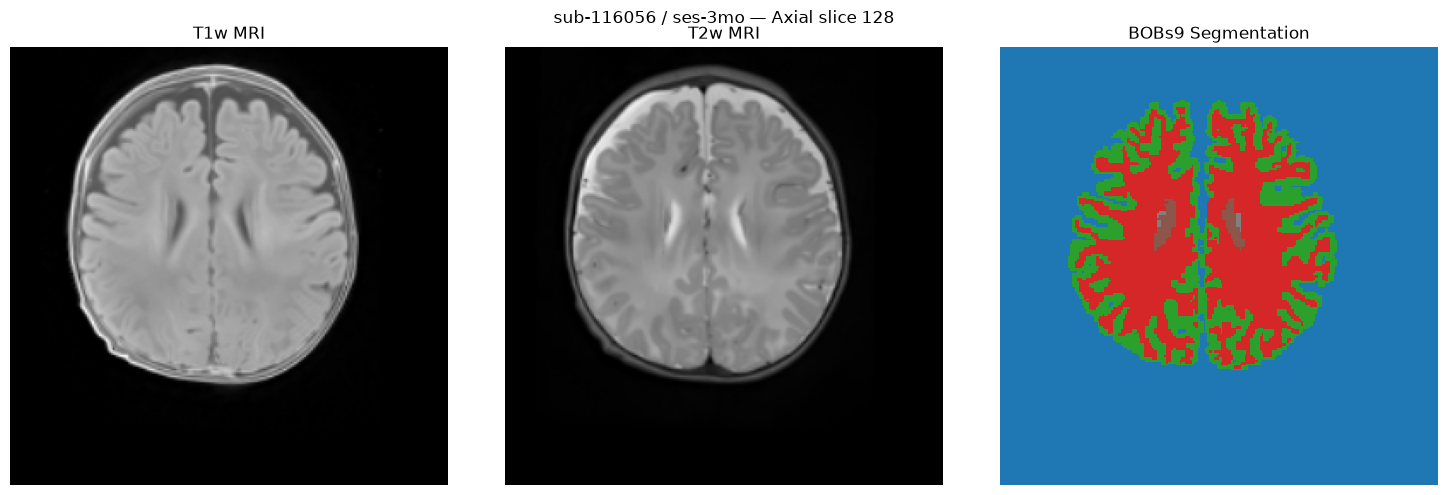

In [6]:
# Choose a central axial slice
z = seg.shape[2] // 2

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(t1[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title("T1w MRI")

axes[1].imshow(t2[:, :, z].T, cmap="gray", origin="lower")
axes[1].set_title("T2w MRI")

axes[2].imshow(
    seg[:, :, z].T,
    cmap="tab10",
    origin="lower",
    vmin=0,
    vmax=9,
    interpolation="nearest",
)
axes[2].set_title("BOBs9 Segmentation")

for ax in axes:
    ax.axis("off")

plt.suptitle(f"{sample_session.parent.name} / {sample_session.name} — Axial slice {z}")
plt.tight_layout()
plt.show()

**What I see:** T1w and T2w show different tissue contrast. The BOBs9 mask covers the brain region, but looking at the mask alone is not enough to judge its boundaries. Label `0` is background (shown in blue by the colormap).

### 2.3 Segmentation overlay

I overlay BOBs9 on each MRI to check whether the segmented regions follow the visible anatomy.

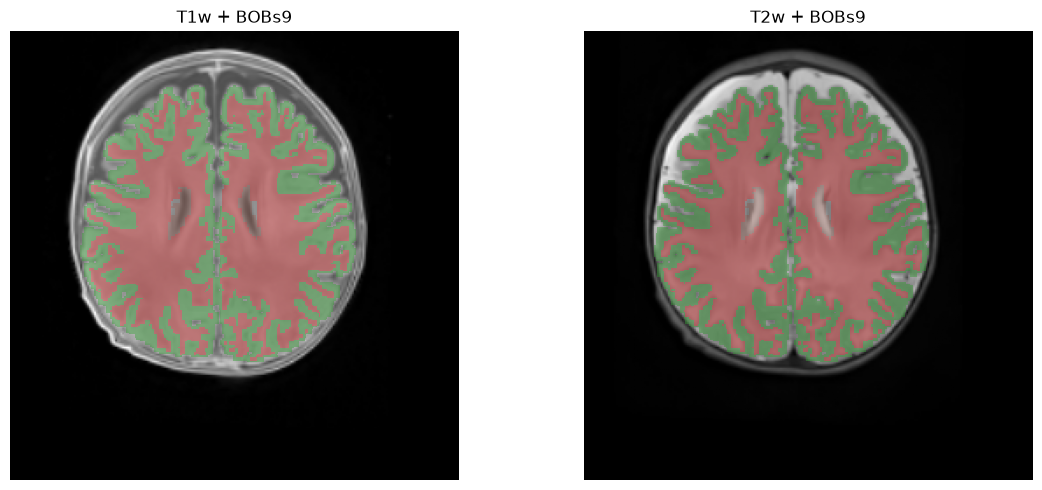

In [7]:
# Overlay BOBs9 on the same axial slice
z = seg.shape[2] // 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, volume, title in zip(axes, [t1, t2], ["T1w + BOBs9", "T2w + BOBs9"]):
    ax.imshow(volume[:, :, z].T, cmap="gray", origin="lower")

    # Hide background label 0
    masked_seg = np.ma.masked_where(seg[:, :, z] == 0, seg[:, :, z])

    ax.imshow(
        masked_seg.T,
        cmap="tab10",
        vmin=0,
        vmax=9,
        alpha=0.4,
        origin="lower",
        interpolation="nearest",
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

**What I see:** The mask appears reasonably aligned with both modalities in this axial slice, with no obvious large shift. This is only a visual check of one slice, not a full segmentation-quality assessment.

### 2.4 Three anatomical planes

I also look at sagittal, coronal and axial views. A single plane might hide problems that are easier to see from another direction.

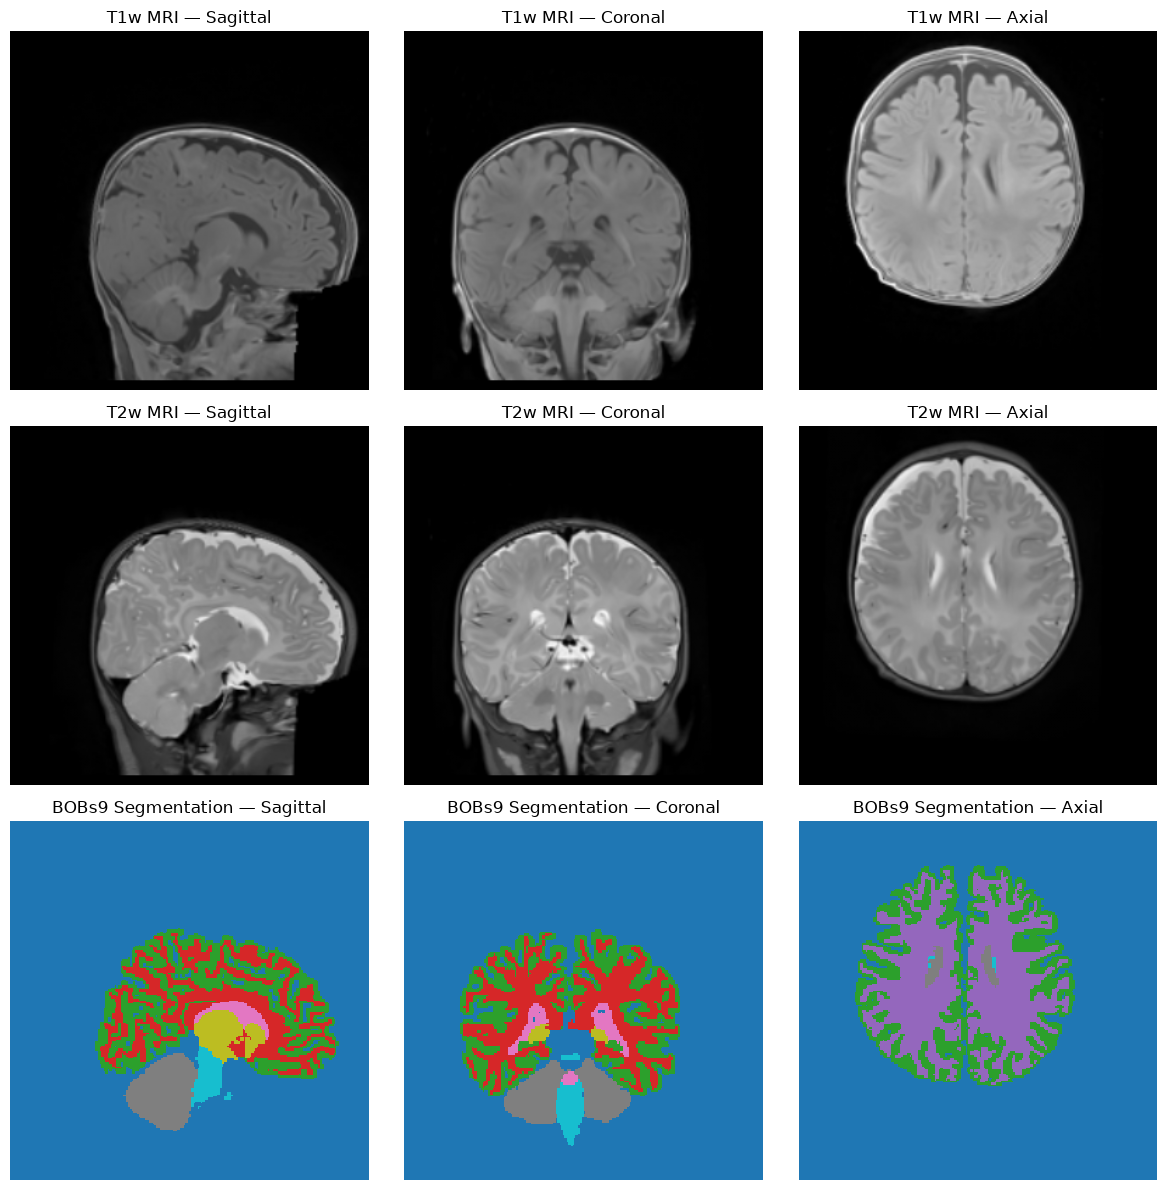

In [8]:
# Central slices for each anatomical plane
slices = {
    "Sagittal": (0, t1.shape[0] // 2),
    "Coronal": (1, t1.shape[1] // 2),
    "Axial": (2, t1.shape[2] // 2),
}

volumes = [
    ("T1w MRI", t1, "gray"),
    ("T2w MRI", t2, "gray"),
    ("BOBs9 Segmentation", seg, "tab10"),
]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, (name, volume, cmap) in enumerate(volumes):
    for col, (plane, (axis, index)) in enumerate(slices.items()):
        slice_data = np.take(volume, index, axis=axis)

        axes[row, col].imshow(
            slice_data.T,
            cmap=cmap,
            origin="lower",
            interpolation="nearest" if name == "BOBs9 Segmentation" else "bilinear",
        )

        axes[row, col].set_title(f"{name} — {plane}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

**What I see:** The major segmented structures look anatomically plausible across the three views. The contrast differs between T1w and T2w, as expected. I cannot assess fine boundary accuracy from these central slices alone.

## 3. Segmentation labels

### 3.1 Label frequencies in one session

I count voxels per label to see whether some classes are much smaller than others. This matters because a model could favor large classes, especially background.

,Label,Voxel count,Percentage (%)
0,0,15085653,89.917499
1,2,704311,4.198021
2,3,701417,4.180771
3,5,27710,0.165164
4,6,148863,0.887293
5,7,70675,0.421256
6,8,27430,0.163496
7,9,11157,0.066501


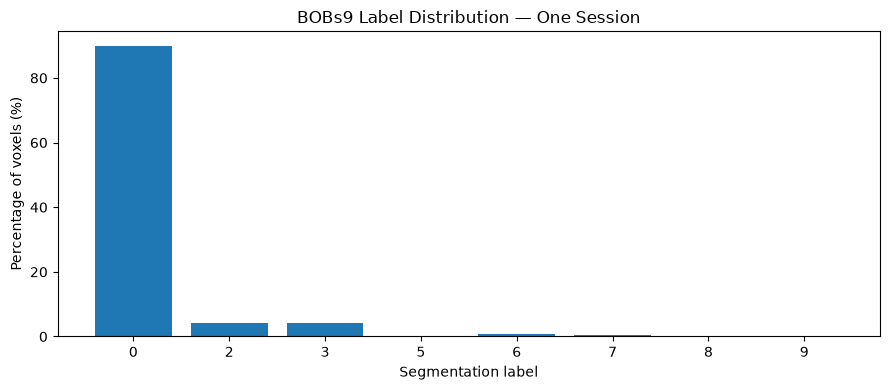

In [9]:
# Count voxels for each segmentation label
label_counts = count_segmentation_labels(seg)

total_voxels = seg.size

label_df = pd.DataFrame(
    {"Label": list(label_counts.keys()), "Voxel count": list(label_counts.values())}
)

label_df["Percentage (%)"] = 100 * label_df["Voxel count"] / total_voxels

display(label_df)

# Visualize label distribution
plt.figure(figsize=(9, 4))

plt.bar(label_df["Label"].astype(str), label_df["Percentage (%)"])

plt.xlabel("Segmentation label")
plt.ylabel("Percentage of voxels (%)")
plt.title("BOBs9 Label Distribution — One Session")

plt.tight_layout()
plt.show()

**What I found:** About **90%** of the voxels are background. Labels `2` and `3` account for most foreground voxels; several other labels are below 1%.

This is similar to FeTA: during training and evaluation, we should account for class imbalance and report **per-class Dice/HD95**, not just voxel accuracy.

### 3.2 Labels across all sessions

I repeat the count for every BOBs9 mask to check whether the imbalance is consistent and whether any label is missing from a session.

,Label,Voxel count,Percentage (%)
0,0,1073304835,90.104160
1,2,52872588,4.438665
2,3,43484970,3.650572
3,5,1853431,0.155596
4,6,11804451,0.990986
5,7,5341967,0.448459
6,8,1657950,0.139185
7,9,862144,0.072377


Unique labels across dataset: [0, 2, 3, 5, 6, 7, 8, 9]

Number of labels per session:


num_labels
8    71
Name: count, dtype: int64

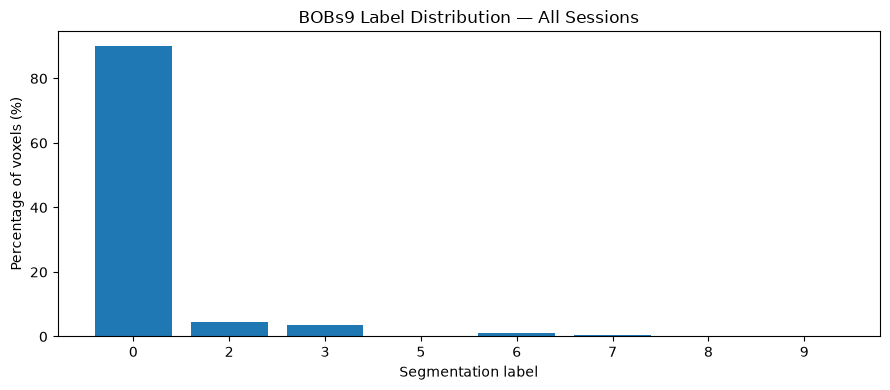

In [10]:
# Sum voxel counts across all BOBs9 masks (one mask per session)
all_label_counts = Counter()
session_labels = []

for seg_path in bobs9_files:
    _, segmentation = load_nifti(seg_path, is_segmentation=True)

    counts = count_segmentation_labels(segmentation)
    all_label_counts.update(counts)

    session_labels.append(
        {
            "session": seg_path.parent.parent.name,
            "subject": seg_path.parent.parent.parent.name,
            "labels": sorted(counts.keys()),
            "num_labels": len(counts),
        }
    )

# Aggregate voxel distribution
total_voxels = sum(all_label_counts.values())

dataset_label_df = pd.DataFrame(
    {
        "Label": sorted(all_label_counts.keys()),
        "Voxel count": [
            all_label_counts[label] for label in sorted(all_label_counts.keys())
        ],
    }
)

dataset_label_df["Percentage (%)"] = (
    100 * dataset_label_df["Voxel count"] / total_voxels
)

display(dataset_label_df)

print("Unique labels across dataset:", sorted(all_label_counts.keys()))

# Check number of labels present in each session
session_labels_df = pd.DataFrame(session_labels)

print("\nNumber of labels per session:")
display(session_labels_df["num_labels"].value_counts().sort_index())

# Plot aggregated label distribution
plt.figure(figsize=(9, 4))

plt.bar(dataset_label_df["Label"].astype(str), dataset_label_df["Percentage (%)"])

plt.xlabel("Segmentation label")
plt.ylabel("Percentage of voxels (%)")
plt.title("BOBs9 Label Distribution — All Sessions")
plt.tight_layout()
plt.show()

**What I found:** All **71 sessions** contain the same eight label values (`0, 2, 3, 5, 6, 7, 8, 9`). Across the dataset, background makes up **90.10%** of voxels. The foreground classes are strongly imbalanced.

The name *BOBs9* does not tell us what these integer values mean; we still need the anatomical label mapping before comparing them with FeTA.

## 4. MRI properties across the dataset

### 4.1 Shape, spacing and orientation

The example session looked consistent. Now I check whether this is true for **all 71 sessions**, since differences here would affect preprocessing.

In [11]:
# Inspect spatial properties across all sessions
spatial_records = []

for session in sessions:
    anat_dir = session / "anat"

    paths = {
        "T1w": next(anat_dir.glob("*_T1w.nii.gz")),
        "T2w": next(anat_dir.glob("*_T2w.nii.gz")),
        "BOBs9": next(anat_dir.glob("*_desc-bobs9_dseg.nii.gz")),
    }

    images = {name: nib.load(str(path)) for name, path in paths.items()}

    for name, img in images.items():
        spatial_records.append(
            {
                "subject": session.parent.name,
                "session": session.name,
                "modality": name,
                "shape": img.shape,
                "spacing": img.header.get_zooms()[:3],
                "orientation": nib.aff2axcodes(img.affine),
            }
        )

spatial_df = pd.DataFrame(spatial_records)

for modality in ["T1w", "T2w", "BOBs9"]:
    subset = spatial_df[spatial_df["modality"] == modality]

    print(f"\n{modality}:")
    print("Shapes:", subset["shape"].value_counts().to_dict())
    print("Spacings:", subset["spacing"].value_counts().to_dict())
    print("Orientations:", subset["orientation"].value_counts().to_dict())


T1w:
Shapes: {(256, 256, 256): 71}
Spacings: {(np.float32(0.75), np.float32(0.75), np.float32(0.75)): 71}
Orientations: {('R', 'A', 'S'): 71}

T2w:
Shapes: {(256, 256, 256): 71}
Spacings: {(np.float32(0.75), np.float32(0.75), np.float32(0.75)): 71}
Orientations: {('R', 'A', 'S'): 71}

BOBs9:
Shapes: {(256, 256, 256): 71}
Spacings: {(np.float32(0.75), np.float32(0.75), np.float32(0.75)): 71}
Orientations: {('R', 'A', 'S'): 71}


**What I found:** Every T1w, T2w and BOBs9 volume has shape **256³**, spacing **0.75 mm** in all directions, and **RAS** orientation.

Unlike the FeTA volumes we inspected, `resampled75` is already standardized in these properties. That does not mean all preprocessing is finished.

### 4.2 Matching MRI and mask coordinates

A matching shape is not enough: I also compare affine matrices for T1w, T2w and BOBs9 in every session.

In [12]:
alignment_records = []

for session in sessions:
    anat_dir = session / "anat"

    t1_img = nib.load(str(next(anat_dir.glob("*_T1w.nii.gz"))))
    t2_img = nib.load(str(next(anat_dir.glob("*_T2w.nii.gz"))))
    seg_img = nib.load(str(next(anat_dir.glob("*_desc-bobs9_dseg.nii.gz"))))

    alignment_records.append(
        {
            "subject": session.parent.name,
            "session": session.name,
            "T1w–T2w": np.allclose(t1_img.affine, t2_img.affine, atol=1e-6),
            "T1w–BOBs9": np.allclose(t1_img.affine, seg_img.affine, atol=1e-6),
            "T2w–BOBs9": np.allclose(t2_img.affine, seg_img.affine, atol=1e-6),
        }
    )

alignment_df = pd.DataFrame(alignment_records)

print("Aligned sessions:")
display(alignment_df.iloc[:, 2:].sum())

misaligned = alignment_df[~alignment_df.iloc[:, 2:].all(axis=1)]

print("\nSessions with affine mismatches:", len(misaligned))
display(misaligned)

Aligned sessions:


T1w–T2w      71
T1w–BOBs9    71
T2w–BOBs9    71
dtype: int64


Sessions with affine mismatches: 0


,subject,session,T1w–T2w,T1w–BOBs9,T2w–BOBs9


**What I found:** All **71/71 sessions** have matching affines for T1w–T2w, T1w–BOBs9 and T2w–BOBs9.

The files share a voxel grid, so no extra registration is indicated by these checks. Matching affines alone do not prove perfect anatomical registration.

### 4.3 Intensity variation across scans

I compare the minimum, maximum, mean and standard deviation of each MRI volume. Even with the same image size, MRI intensity scales may differ between scans.

In [13]:
# Collect MRI intensity statistics across all sessions
intensity_records = []

for session in sessions:
    anat_dir = session / "anat"

    for modality in ["T1w", "T2w"]:
        path = next(anat_dir.glob(f"*_{modality}.nii.gz"))

        img, volume = load_nifti(path)
        stats = inspect_volume(img, volume)

        intensity_records.append(
            {
                "subject": session.parent.name,
                "session": session.name,
                "modality": modality,
                "min": stats["min"],
                "max": stats["max"],
                "mean": stats["mean"],
                "std": stats["std"],
            }
        )

intensity_df = pd.DataFrame(intensity_records)

# Summarize intensity statistics by modality
display(
    intensity_df.groupby("modality")[["min", "max", "mean", "std"]]
    .agg(["min", "median", "max"])
    .round(2)
)

min                 max                  mean                  std  \
          min median  max     min  median     max   min median    max    min   
modality                                                                       
T1w       0.0    0.0  0.0  116.81  308.95  570.93  8.42  19.40  31.02  16.46   
T2w       0.0    0.0  0.0   60.11  158.59  302.94  4.80  12.72  24.63  11.16   

                        
         median    max  
modality                
T1w       40.23  59.52  
T2w       28.01  56.12

**What I found:** Intensity ranges vary substantially across sessions for both T1w and T2w. For example, the **maximum T2w intensity** ranges from about **60 to 303**.

These statistics include many zero-valued background voxels, so I check nonzero intensities next. Normalization may help, but we should follow the pretrained model's expected preprocessing.

### 4.4 Nonzero-voxel intensities

I repeat the statistics using voxels with intensity **`> 0`**, to reduce the effect of the large zero background. This is **not** the same as using a brain mask.

In [14]:
foreground_records = []

for session in sessions:
    anat_dir = session / "anat"

    for modality in ["T1w", "T2w"]:
        path = next(anat_dir.glob(f"*_{modality}.nii.gz"))
        _, volume = load_nifti(path)

        foreground = volume[volume > 0]

        foreground_records.append(
            {
                "subject": session.parent.name,
                "session": session.name,
                "modality": modality,
                "mean": float(np.mean(foreground)),
                "std": float(np.std(foreground)),
                "p1": float(np.percentile(foreground, 1)),
                "p99": float(np.percentile(foreground, 99)),
            }
        )

foreground_df = pd.DataFrame(foreground_records)

display(
    foreground_df.groupby("modality")[["mean", "std", "p1", "p99"]]
    .agg(["min", "median", "max"])
    .round(2)
)

mean                  std                  p1                 p99  \
           min median    max    min median    max   min median   max    min   
modality                                                                      
T1w       15.4  38.07  61.38  19.69  49.18  80.17  0.01   0.04  0.10  53.37   
T2w        9.0  24.22  47.71  12.99  34.70  70.71  0.00   0.00  0.01  38.49   

                          
          median     max  
modality                  
T1w       136.97  229.16  
T2w       105.52  230.45

**What I found:** The intensity variation remains after removing zero voxels: for example, the mean T2w intensity ranges from **9.0 to 47.7** between sessions.

Normalization is worth considering, but it should not be chosen blindly: infant tissue contrast also changes with age. The foundation model's preprocessing requirements will guide this decision.

## 5. Participant and session information

### 5.1 Metadata and repeated sessions

I inspect `participants.csv` to understand the sample and check whether some infants have more than one scan. This matters when creating train/validation/test splits.

In [15]:
# Load participant and session metadata
metadata_path = BOBS_DIR / "participants.csv"

metadata_df = pd.read_csv(metadata_path)

print("Metadata shape:", metadata_df.shape)
print("\nColumns:")
print(metadata_df.columns.tolist())

print("\nFirst 5 rows:")
display(metadata_df.head())

print("\nMissing values:")
display(metadata_df.isna().sum())

# Number of sessions per participant
sessions_per_subject = metadata_df.groupby("participant_id").size()

print("\nNumber of unique participants:", metadata_df["participant_id"].nunique())

print("Total sessions:", len(metadata_df))

print("\nSessions per participant:")
display(sessions_per_subject.value_counts().sort_index())

Metadata shape: (71, 7)

Columns:
['participant_id', 'session_id', 'age', 'gestational_age_at_birth', 'sex', 'age_at_scan_weeks', 'pma_weeks']

First 5 rows:


,participant_id,session_id,age,gestational_age_at_birth,sex,age_at_scan_weeks,pma_weeks
0,sub-116056,ses-3mo,3.6,40.4,Male,14.4,54.8
1,sub-116845,ses-3mo,3.6,37.7,Female,14.4,52.1
2,sub-116845,ses-6mo,6.5,37.7,Female,26.0,63.7
3,sub-176427,ses-5mo,5.0,41.7,Female,20.0,61.7
4,sub-198202,ses-5mo,5.9,40.1,Male,23.6,63.7



Missing values:


participant_id              0
session_id                  0
age                         0
gestational_age_at_birth    0
sex                         0
age_at_scan_weeks           0
pma_weeks                   0
dtype: int64


Number of unique participants: 51
Total sessions: 71

Sessions per participant:


1    34
2    14
3     3
Name: count, dtype: int64

**What I found:** The metadata contains **71 sessions from 51 infants**, with no missing values in the listed columns. **34** infants have one session, **14** have two and **3** have three.

Repeated scans from the same infant must stay in the same split to avoid data leakage.

### 5.2 Age and sex

I look at age because infant brain anatomy and MRI contrast change during development. Here, `age` is **months since birth**; `pma_weeks` is **gestational age at birth + age since birth**, in weeks.

Age distributions are counted **per session**, while sex is counted **per infant** to avoid counting the same child twice.

Age at scan (months):


count    71.00
mean      5.34
std       2.31
min       1.00
25%       3.25
50%       5.50
75%       7.25
max       9.40
Name: age, dtype: float64


Postmenstrual age (weeks):


count    71.00
mean     61.19
std       8.97
min      46.00
25%      52.80
50%      61.30
75%      68.75
max      77.70
Name: pma_weeks, dtype: float64


Sex distribution (participants):


sex
Female    31
Male      20
Name: count, dtype: int64

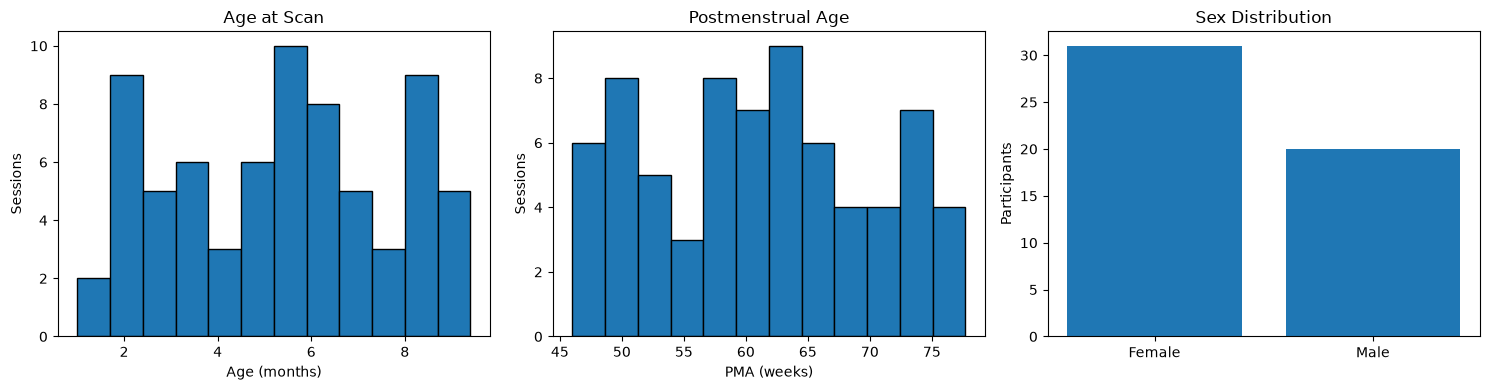

In [16]:
# Age statistics (one row per imaging session)
print("Age at scan (months):")
display(metadata_df["age"].describe().round(2))

print("\nPostmenstrual age (weeks):")
display(metadata_df["pma_weeks"].describe().round(2))

# One sex entry per participant to avoid counting repeated sessions
subject_metadata = metadata_df.drop_duplicates("participant_id")

print("\nSex distribution (participants):")
display(subject_metadata["sex"].value_counts())

# Visualize distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(metadata_df["age"], bins=12, edgecolor="black")
axes[0].set_title("Age at Scan")
axes[0].set_xlabel("Age (months)")
axes[0].set_ylabel("Sessions")

axes[1].hist(metadata_df["pma_weeks"], bins=12, edgecolor="black")
axes[1].set_title("Postmenstrual Age")
axes[1].set_xlabel("PMA (weeks)")
axes[1].set_ylabel("Sessions")

sex_counts = subject_metadata["sex"].value_counts()
axes[2].bar(sex_counts.index, sex_counts.values)
axes[2].set_title("Sex Distribution")
axes[2].set_ylabel("Participants")

plt.tight_layout()
plt.show()

**What I found:** Scans were acquired between **1 and 9.4 months** of age (mean **5.34 months**). PMA ranges from **46 to 77.7 weeks**. There are **31 female** and **20 male** participants.

Age could be useful for **subgroup evaluation** later. For now, the planned model input is the MRI, not the metadata (to confirm with the lab).

### 5.3 Existing data splits

The folder includes `splits_40_10_15_35.csv`. I check how sessions are distributed and whether the same participant appears in more than one split.

In [17]:
# Load predefined dataset splits
splits_path = BOBS_DIR / "splits_40_10_15_35.csv"
splits_df = pd.read_csv(splits_path)

print("Split file shape:", splits_df.shape)
print("\nColumns:", splits_df.columns.tolist())

print("\nSessions per split:")
display(splits_df["splits"].value_counts())

print("\nUnique participants per split:")
display(splits_df.groupby("splits")["participant_id"].nunique())

# A participant must not appear in more than one split
participant_split_counts = splits_df.groupby("participant_id")["splits"].nunique()

leaking_participants = participant_split_counts[participant_split_counts > 1]

print("\nParticipants appearing in multiple splits:", len(leaking_participants))

display(leaking_participants)

Split file shape: (71, 6)

Columns: ['participant_id', 'session_id', 'session_folder', 'splits', 'pathological', 'sex']

Sessions per split:


splits
train      29
test_ho    26
test_i     11
val         5
Name: count, dtype: int64


Unique participants per split:


splits
test_ho    18
test_i      8
train      20
val         5
Name: participant_id, dtype: int64


Participants appearing in multiple splits: 0


Series([], Name: splits, dtype: int64)

**What I found:** There are **29 train**, **5 validation**, **11 `test_i`** and **26 `test_ho`** sessions. No participant appears in more than one split.

These splits are leakage-free at the participant level. We still need to confirm what `test_i` and `test_ho` represent and whether to reuse this split protocol for our experiments.

## 6. Basic data quality checks

I use `check_volume_quality()` to look for NaN/infinite MRI values, constant images, empty masks, non-integer labels and labels outside the set observed in BOBs9.

These checks catch basic data problems, **not** subtle anatomical errors.

In [18]:
# Labels observed in this dataset (not an externally verified anatomical mapping)
expected_labels = set(all_label_counts.keys())

quality_records = []

for session in sessions:
    anat_dir = session / "anat"

    seg_path = next(anat_dir.glob("*_desc-bobs9_dseg.nii.gz"))
    _, seg = load_nifti(seg_path, is_segmentation=True)

    for modality in ["T1w", "T2w"]:
        mri_path = next(anat_dir.glob(f"*_{modality}.nii.gz"))
        _, mri = load_nifti(mri_path)

        checks = check_volume_quality(mri, seg, expected_labels)

        quality_records.append(
            {
                "subject": session.parent.name,
                "session": session.name,
                "modality": modality,
                **checks,
            }
        )

quality_df = pd.DataFrame(quality_records)

print("Total MRI–segmentation pairs:", len(quality_df))

# Summarize quality issues
quality_columns = [
    "mri_nan",
    "mri_inf",
    "mri_constant",
    "seg_nan",
    "seg_inf",
    "seg_non_integer",
    "seg_empty",
]

print("\nQuality issues:")
display(quality_df[quality_columns].sum())

print(
    "\nPairs with unexpected labels:", quality_df["unexpected_labels"].apply(bool).sum()
)

Total MRI–segmentation pairs: 142

Quality issues:


mri_nan            0
mri_inf            0
mri_constant       0
seg_nan            0
seg_inf            0
seg_non_integer    0
seg_empty          0
dtype: int64


Pairs with unexpected labels: 0


**What I found:** All **142 MRI–mask pair checks** (71 T1w and 71 T2w, each compared with BOBs9) passed. No invalid values, empty masks or unexpected labels were detected.

The allowed label set comes from this dataset itself; its **anatomical meaning still needs external confirmation**.

## 7. What I take from this EDA

The `resampled75` data looks consistent and ready for the **next planning stage**, although we have not preprocessed it for training yet.

- **Data:** 51 infants, 71 sessions, with T1w/T2w images and BOBs9 masks.
- **Spatial checks:** All volumes are 256³, 0.75 mm, RAS; MRI–mask affines match across sessions.
- **Labels:** The same eight integer values occur in every BOBs9 mask. Background is about 90% of voxels, so class imbalance matters.
- **Intensities:** Scales vary between scans, even after excluding zero voxels.
- **Metadata:** Age varies across infants, and some infants have repeated sessions. The provided splits show no participant leakage.
- **Quality:** No issues were flagged by the basic automated checks.

**Still to decide with Daniela / the lab:**
1. Whether to use **T2w only** (easier to compare with FeTA) or include T1w.
2. The **BOBs9 anatomical label mapping** and whether it can be matched to FeTA labels.
3. The **preprocessing expected by the foundation model**, especially intensity normalization.
4. Whether to keep the provided splits and what `test_i` / `test_ho` mean.

The goal of this notebook was to understand the data, not to make those modeling choices yet.